In [72]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss_and_mae, evaluate_model 

from sklearn.model_selection import train_test_split
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import tensorflow as tf
from sklearn.preprocessing import StandardScaler

from pandas import DataFrame
from pandas import concat

<h3>Importing The Data

,Unnamed: 0,point,time,x,y,x_rb,y_rb,s0,s1,s2,...,track_cy,track_radius,roi_x_min,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm
0,0,0.0,1.2720,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,260.0,6.0,154.0,120.0,434.0,400.0,0.0,0.0,0.000000,0.000000
1,1,1.0,2.6999,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,260.0,6.0,154.0,120.0,434.0,400.0,0.0,0.0,0.000000,0.000000
2,2,0.0,23.0354,1.2,1.2,1.200031,1.2,6144.0,-8393.0,2249.0,...,72.0,6.0,-60.0,-68.0,220.0,212.0,-214.0,-188.0,1.945455,1.709091
3,3,1.0,25.1267,1.1,1.2,1.099897,1.2,6144.0,-7949.0,1805.0,...,76.0,6.0,-46.0,-64.0,234.0,216.0,-200.0,-184.0,1.818182,1.672727
4,4,2.0,27.2019,1.0,1.2,0.999989,1.2,6144.0,-7506.0,1362.0,...,76.0,6.0,-32.0,-64.0,248.0,216.0,-186.0,-184.0,1.690909,1.672727


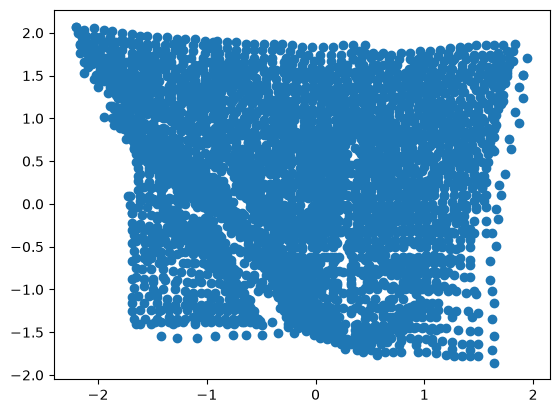

In [2]:
data_concat = pd.read_csv("processed_data/16Oct_data_corrected.csv")
display(data_concat.head())
data_concat.dtypes
plt.scatter(data_concat["cx_mm"], data_concat["cy_mm"])

<h3>Correcting The Data - Remove NaNs and convert to float32

In [3]:
data_concat = data_concat.astype("float32")
data_concat = data_concat.dropna()

<h3>MLP Inverse - with displacement?

In [68]:
data_concat["cx_diff"] = data_concat["cx_mm"].diff().round(1)
data_concat["cy_diff"] = data_concat["cy_mm"].diff().round(1)
data_concat["cx_direction"] =  np.sign(data_concat["cx_diff"])
data_concat["cy_direction"] = np.sign(data_concat["cy_diff"])

# dataset_test = data_concat.tail(442).reset_index()
all_data = data_concat[["cx_mm", "cy_mm","cx_direction","cy_direction", "s0", "s1", "s2"]].drop(data_concat.tail(442).index).drop(0) #reset indexes as multiple datapoints combined
#"cx_diff","cy_diff",
all_data.head(50)

,cx_mm,cy_mm,cx_direction,cy_direction,s0,s1,s2
1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
2,1.945455,1.709091,1.0,1.0,6144.0,-8393.0,2249.0
3,1.818182,1.672727,-1.0,0.0,6144.0,-7949.0,1805.0
4,1.690909,1.672727,-1.0,0.0,6144.0,-7506.0,1362.0
5,1.527273,1.636364,-1.0,0.0,6144.0,-7063.0,919.0
6,1.345455,1.618182,-1.0,0.0,6144.0,-6619.0,475.0
7,1.163636,1.600000,-1.0,0.0,6144.0,-6176.0,32.0
8,1.000000,1.581818,-1.0,0.0,6144.0,-5732.0,-412.0
9,0.854545,1.581818,-1.0,0.0,6144.0,-5289.0,-855.0
10,0.690909,1.563636,-1.0,0.0,6144.0,-4846.0,-1298.0


In [73]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(32, activation='relu'),#  kernel_regularizer='l1'),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

    model.summary()

    return model

def train_model(model, X_train, y_train, epochs=100, patience=30, verbose=0):
    # callbacks = [
    # tf.keras.callbacks.EarlyStopping(
    #     monitor='val_loss',
    #     patience=patience,
    #     restore_best_weights=True
    # )]

    history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    verbose=verbose, 
    epochs=epochs,
    # callbacks=callbacks
    )
    # print(patience)
    return history

def plot_motors(y_test, y_pred, lims): 
    fig, axs = plt.subplots(1, 3)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()

In [70]:
scalerX = StandardScaler().fit(all_data[["cx_mm", "cy_mm", "cx_direction","cy_direction"]])
scalerY = StandardScaler().fit(all_data[["s0", "s1", "s2"]])
X_scaled = scalerX.transform(all_data[["cx_mm", "cy_mm", "cx_direction","cy_direction"]])
y_scaled = scalerY.transform(all_data[["s0", "s1", "s2"]])

In [71]:
# X_train = dataset[["cx_mm", "cy_mm", "cx_direction","cy_direction"]].drop(0) #, "cx_diff", "cy_diff"
# y_train_all = dataset[["s0", "s1", "s2"]].drop(0)

# X_test = dataset_test[["cx_mm", "cy_mm", "cx_direction","cy_direction"]].drop(0) #, "cx_diff", "cy_diff"
# y_test_all = dataset_test[["s0", "s1", "s2"]].drop(0)


# # print(y_train_all)
# y_train = y_train_all #[["s0", "s1"]] #calculate s2 from s2 = -(s0 + s1) to ensure they all sum to 0
# y_test = y_test_all #[["s0", "s1"]]

# scalerX = StandardScaler().fit(X_train)
# scalerY = StandardScaler().fit(y_train)

# X_train_scaled = scalerX.transform(X_train)
# y_train_scaled = scalerY.transform(y_train)

# X_test_scaled = scalerX.transform(X_test)
# y_test_scaled = scalerY.transform(y_test)


# model = build_nn_model(X_train_scaled.shape[1], y_train_scaled.shape[1])
# model.summary() #investigate

Fold 0:
  Train: index=0 to 781 
  Test:  index=782 to 1560


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_22 (Dense)                │ (None, 32)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 259 (1.01 KB)

 Trainable params: 259 (1.01 KB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 259 (1.01 KB)

 Trainable params: 259 (1.01 KB)

 Non-trainable params: 0 (0.00 B)


Fold: 2 Results (scaled):
  Overall R2:  0.9398
  Weighted R2: 0.9341
MSE scores for each fold: [0.07346999645233154, 0.030308371409773827, 0.03537103906273842]


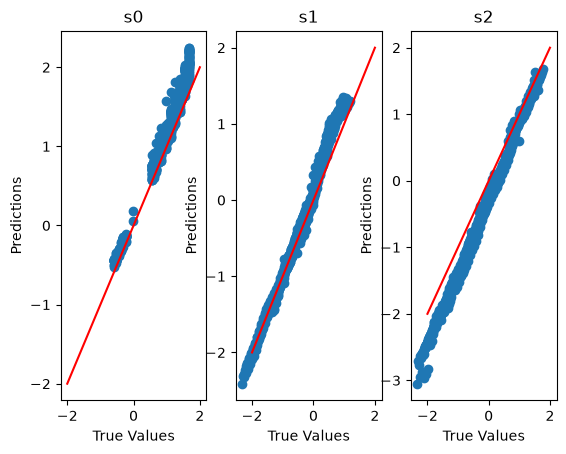

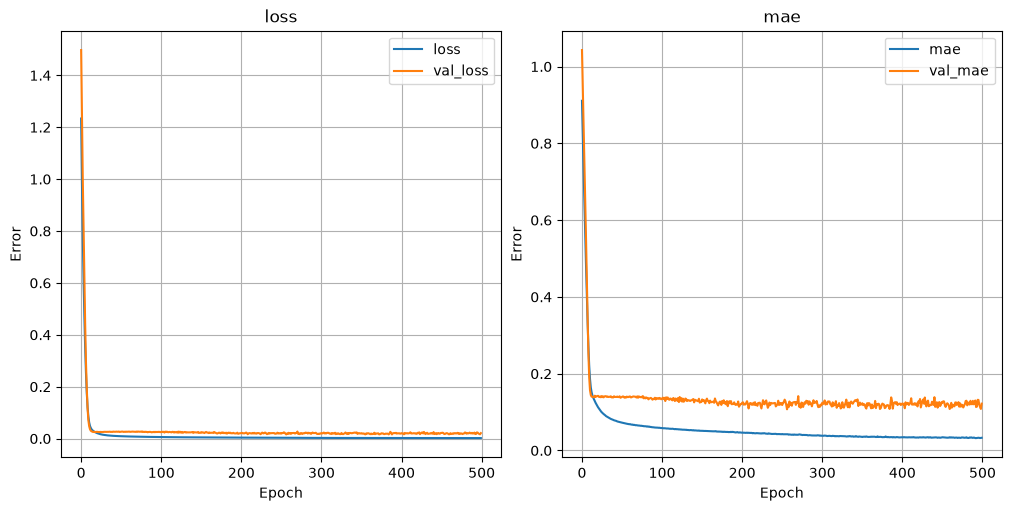

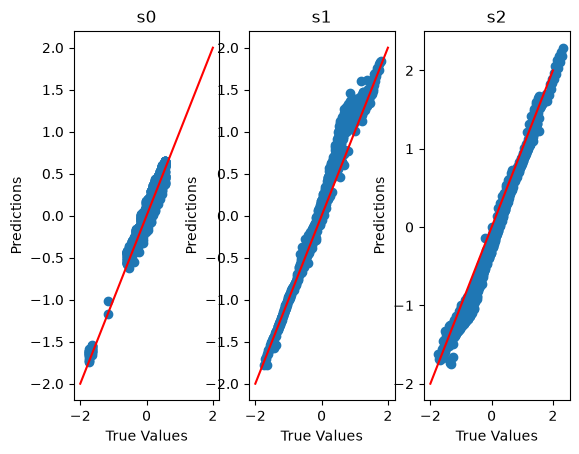

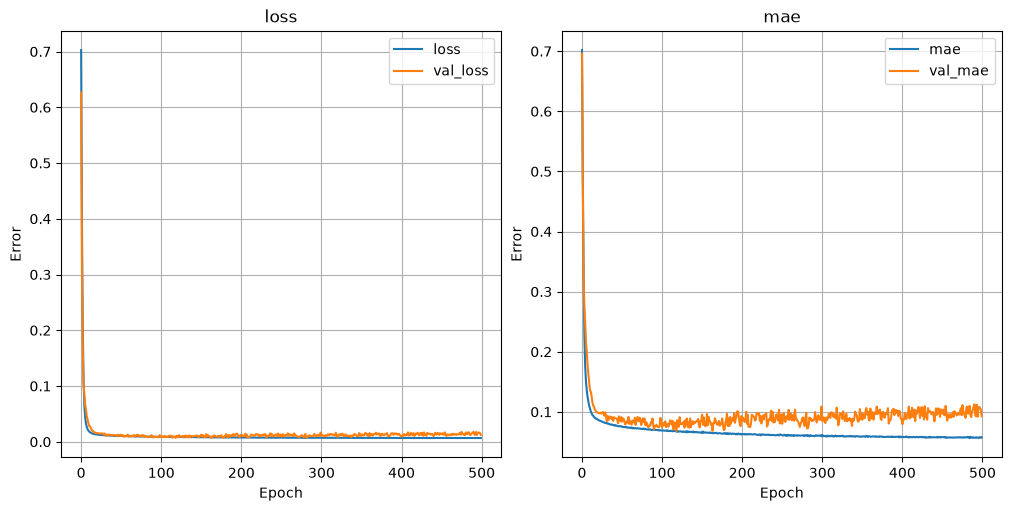

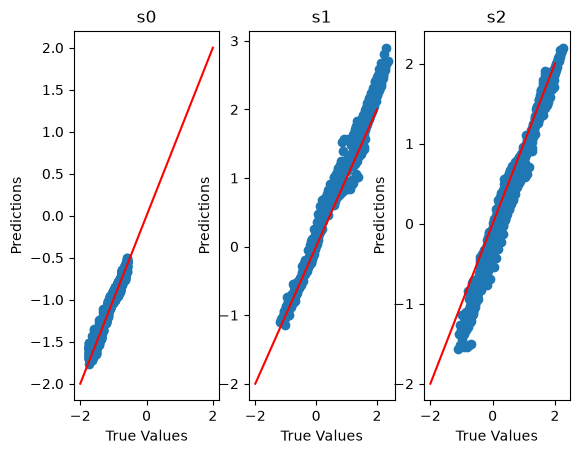

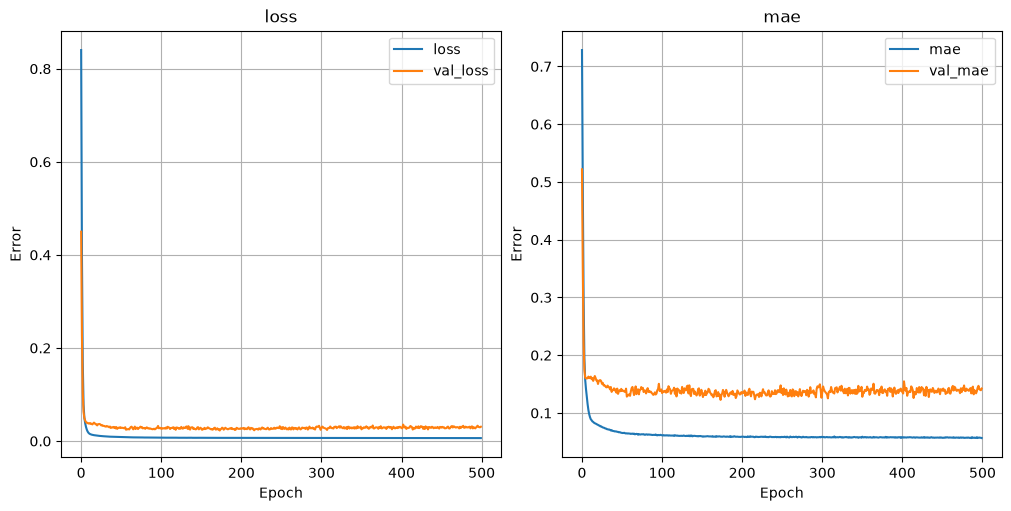

In [77]:
# model = build_nn_model(X_scaled.shape[1], y_scaled.shape[1])

scores = []

X = X_scaled
y = y_scaled

tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = build_nn_model(X_scaled.shape[1], y_scaled.shape[1]) #instantiate new model each time to see difference

    history = train_model(model, X_train, y_train, verbose=0, epochs=500) #, patience=10)
    y_pred = model.predict(X_test, verbose=0)

    evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)
    plot_motors(y_test, y_pred, [-2,2])

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plot_loss_and_mae(history)

print("MSE scores for each fold:", scores)

In [ ]:
y_pred_inverse = scalerY.inverse_transform(y_pred)
y_test_inverse = scalerY.inverse_transform(y_test)
y_pred_inverse = DataFrame(y_pred_inverse)
# y_pred_inverse_all = y_pred_inverse
# y_pred_inverse_all[2]= -(y_pred_inverse_all[0] + y_pred_inverse_all[1])
y_pred_inverse


,0,1,2
0,-2196.910400,6159.289062,-3968.337158
1,-2143.036621,5517.870605,-3509.318604
2,-2128.384277,6646.323242,-4498.308105
3,-2203.253418,6957.458008,-4736.910156
4,-2214.952393,7184.455078,-4959.449219
...,...,...,...
436,-4250.299805,6181.685547,-1970.381714
437,-4262.395020,7380.301270,-3177.819092
438,-4308.991699,7994.309082,-3788.710205
439,756.899231,320.698029,-1301.094727


In [60]:
y_test_inverse

array([[-2304.    ,  5364.    , -3060.    ],
       [-2304.    ,  5586.    , -3282.    ],
       [-2304.    ,  6029.    , -3725.    ],
       ...,
       [-5120.    ,  6994.    , -1874.0001],
       [    0.    ,     0.    ,     0.    ],
       [    0.    ,     0.    ,     0.    ]],
      shape=(441, 3), dtype=float32)

441 441


Text(0.5, 0.98, '16th Oct Windowed Test Predictions not flattened')

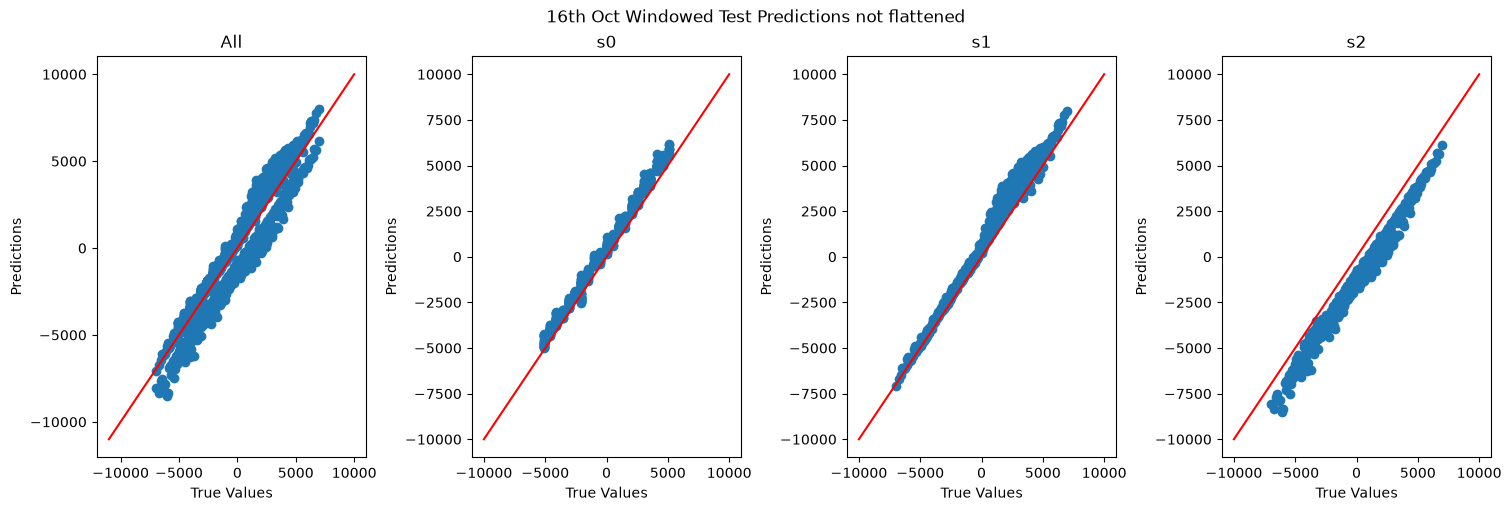

In [62]:
fig, axs = plt.subplots(1,4, figsize=(15,5), constrained_layout=True)
subplot = axs[0]
subplot.scatter(y_test_inverse, y_pred_inverse)
subplot.set_xlabel('True Values')
subplot.set_ylabel('Predictions')
lims = [-11000, 10000]
# plt.xlim(lims)
# plt.ylim(lims)
_ = subplot.plot(lims, lims, color="red")
subplot.set_title("All")
print(len(y_test_scaled), len(y_pred))

for i, label in enumerate(['s0', 's1', 's2']):
    subplot = axs[i+1]
    subplot.scatter(y_test_all[label], y_pred_inverse[i])
    lims = [-10000, 10000]
    subplot.set_xlabel('True Values')
    subplot.set_ylabel('Predictions')
    # subplot.set_xlim(lims)
    # subplot.set_ylim(lims)
    _ =subplot.plot(lims, lims, color="red")
    subplot.set_title(label)
fig.suptitle("16th Oct Windowed Test Predictions not flattened")

<h2> Predicting for normal square - snake



In [ ]:
plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
plt.colorbar()

In [ ]:
X_scaled_0020 = scalerX.transform(cxcy_window_0020)

In [ ]:
snake_predictions = model.predict(X_scaled_0020)

In [ ]:
snake_pred_inverse = scalerY.inverse_transform(snake_predictions)

In [ ]:
print(snake_pred_inverse)
np.savetxt("predictions/16Oct_MLP_Window_Pred_snake_mesh.csv", snake_pred_inverse, delimiter=',')